# Ceasul Cuantic al Iașului
## Nivelul 3 — Legătura Copou

> ### Copou, Palatul Universitar, ora 10:20
>
> În Palatul Universitar din Copou se află nodul **Copou** al rețelei. Legătura lui cu Palatul folosea **perechi de qubiți încâlciți** (*entangled*) — iar Umbra a rupt-o.
>
> De ore întregi, nodul Copou încearcă să trimită un mesaj. Dar fără o pereche Bell funcțională, nimeni nu-l poate citi.
>
> Reparați legătura și aflați ce are de spus Copoul.

### Ce veți învăța în acest nivel

- cum lucrați cu **doi qubiți** și cu poarta **CNOT**;
- ce este **încâlcirea** (*entanglement*) și cele patru **stări Bell**;
- cum se trimit **2 biți folosind un singur qubit** (*superdense coding*).

In [2]:
# Rulați această celulă prima. Ea încarcă Qiskit și uneltele provocării.
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from ceas_cuantic import *

ECHIPA = "Don't quit, qubit!"   # COMPLETEAZĂ AICI — același nume în toate notebook-urile
COD_ECHIPA = "UP2U-JRC"     # COMPLETEAZĂ AICI — codul primit de la organizatori
start(ECHIPA, COD_ECHIPA)

Bine ați venit, echipa „Don't quit, qubit!”! Sunteți conectați la serverul provocării.


## 1. Doi qubiți

Doi qubiți au patru stări de bază: $|00\rangle, |01\rangle, |10\rangle, |11\rangle$, deci patru amplitudini. **Atenție la ordine:** Qiskit scrie qubitul 0 în **dreapta**. În $|ab\rangle$, qubitul 0 este b, iar qubitul 1 este a.

Poarta **CNOT** (`qc.cx(control, tinta)`) întoarce qubitul țintă doar dacă qubitul de control este 1:

| intrare (q1 q0) | 00 | 01 | 10 | 11 |
| --- | --- | --- | --- | --- |
| după `cx(0, 1)` | 00 | 11 | 10 | 01 |

## 2. Perechea Bell

Puneți qubitul 0 în superpoziție cu H, apoi aplicați CNOT:

$$|\Phi^+\rangle = \frac{1}{\sqrt2}\left(|00\rangle + |11\rangle\right)$$

Măsurați: obțineți **00** sau **11**, niciodată 01 sau 10. Fiecare qubit, privit singur, e complet aleator — dar cei doi sunt mereu de acord. Asta e încâlcirea.

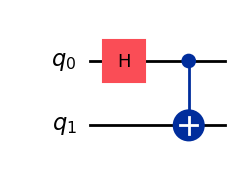

Amplitudini: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]


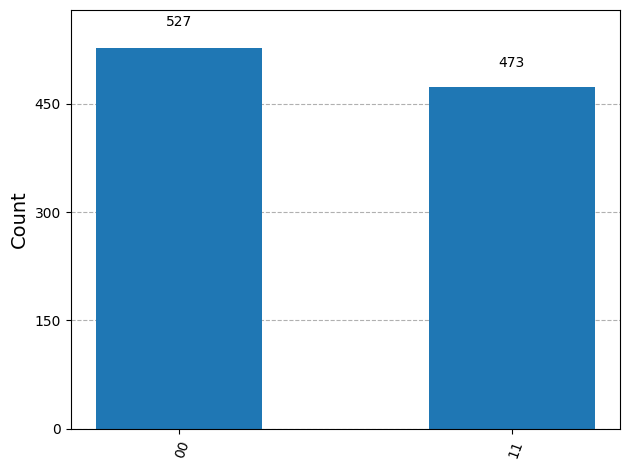

In [5]:
phi_plus = QuantumCircuit(2)
phi_plus.h(0)
phi_plus.cx(0, 1)
display(phi_plus.draw("mpl"))
print("Amplitudini:", np.round(Statevector(phi_plus).data, 3))
plot_histogram(masoara(phi_plus))

<div class="alert alert-block alert-success">
<b>Sarcina 3A — Cele patru stări Bell (80 de puncte)</b>

Pornind de la circuitul pentru Φ⁺, construiți celelalte trei stări Bell (fără măsurători):
<ul>
<li><code>phi_minus</code> = (|00⟩ − |11⟩)/√2</li>
<li><code>psi_plus</code> = (|01⟩ + |10⟩)/√2</li>
<li><code>psi_minus</code> = (|01⟩ − |10⟩)/√2</li>
</ul>
Ce poartă schimbă un „+” într-un „−”? Ce poartă schimbă 00 în 01?
</div>

In [9]:
phi_minus = QuantumCircuit(2)
phi_minus.x(0)
phi_minus.h(0)
phi_minus.cx(0, 1)
# COMPLETEAZĂ AICI

psi_plus = QuantumCircuit(2)
psi_plus.x(1)
psi_plus.h(0)
psi_plus.cx(0, 1)
# COMPLETEAZĂ AICI

psi_minus = QuantumCircuit(2)
psi_minus.x(0)
psi_minus.x(1)
psi_minus.h(0)
psi_minus.cx(0, 1)
# COMPLETEAZĂ AICI

for nume, qc in [("Φ-", phi_minus), ("Ψ+", psi_plus), ("Ψ-", psi_minus)]:
    print(nume, np.round(Statevector(qc).data, 3))

Φ- [ 0.707+0.j  0.   +0.j  0.   +0.j -0.707+0.j]
Ψ+ [0.   +0.j 0.707+0.j 0.707+0.j 0.   +0.j]
Ψ- [ 0.   +0.j -0.707+0.j  0.707+0.j  0.   +0.j]


In [10]:
verifica_3A(phi_plus, phi_minus, psi_plus, psi_minus)

✔ Corect! Sarcina 3A — Stările Bell: +80 puncte.


## 3. Doi biți într-un singur qubit

Nodul Copou și Palatul împart o pereche Bell $|\Phi^+\rangle$: qubitul 0 e la Copou, qubitul 1 la Palat.

Copoul vrea să trimită **2 biți**. Aplică pe qubitul lui una din patru operații — **I, X, Z** sau **Z·X** — și vă trimite **doar qubitul lui**. Fiecare operație transformă perechea într-o altă stare Bell (le-ați construit chiar voi mai sus!).

Voi aveți acum ambii qubiți. Ca să aflați cei 2 biți, trebuie să **decodați**: să transformați fiecare stare Bell înapoi într-o stare de bază (00, 01, 10 sau 11), pe care o măsurați.

Funcția `semnal_copou(i)` vă dă al `i`-lea semnal primit: un circuit cu 2 qubiți în care cutia „Copou” a pregătit deja perechea și a aplicat operația secretă.

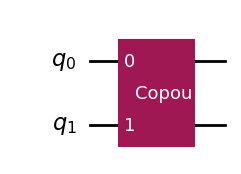

Semnale de primit: 51


In [11]:
semnal = semnal_copou(0)
display(semnal.draw("mpl"))
print("Semnale de primit:", NUMAR_SEMNALE_COPOU)

<div class="alert alert-block alert-success">
<b>Sarcina 3B — Mesajul de la Copou (120 de puncte · clopotul 3)</b>

Completați funcția <code>decodeaza(qc)</code>: ea primește un semnal și trebuie să adauge porțile care transformă starea Bell înapoi într-o stare de bază, apoi măsurarea.<br>
Gândiți-vă: cum ați construit perechea Bell? Ce trebuie făcut ca s-o „desfaceți”?<br><br>
Când verificatorul spune că decodorul funcționează, citiți mesajul cu <code>citeste_mesajul(decodeaza)</code>.<br>
Blocați de tot? <code>kit_de_salvare(3)</code> vă dă mesajul, dar sarcina 3B nu mai aduce puncte și clopotul 3 rămâne stins.
</div>

In [12]:
def decodeaza(qc):
    # COMPLETEAZĂ AICI: adăugați porțile decodorului
    qc.cx(0, 1)
    qc.h(0)

    qc.measure_all()
    return qc


print("Primul semnal decodat:", masoara(decodeaza(semnal_copou(0))))

Primul semnal decodat: {'00': 1000}


In [13]:
verifica_3B(decodeaza)

✔ Corect! Sarcina 3B — Mesajul de la Copou: +120 puncte.
🔔 Clopotul 3 s-a aprins: Mesajul de la Copou decodat.


Citiți acum mesajul cu citeste_mesajul(decodeaza).


In [14]:
mesaj = citeste_mesajul(decodeaza)

Mesaj primit de la Copou: „CHEIA E LA ASACHI”


Fiecare 3 perechi de biți (6 biți) formează o literă, după alfabetul de 6 biți din `ALFABET`. Ce v-a transmis Copoul? Acolo vă așteaptă **nivelul 4**.

<div class="alert alert-block alert-warning">
<b>Provocare extra — Teleportarea (+50 de puncte)</b>

Teleportați starea de la nivelul 1, R<sub>y</sub>(π/3)|0⟩ (cea cu P(1) = 25%), de pe qubitul 0 pe qubitul 2, fără s-o atingeți direct.<br>
Pași: (1) creați o pereche Bell între qubiții 1 și 2; (2) CNOT(0, 1), apoi H pe qubitul 0; (3) folosiți porți controlate: CNOT(1, 2) și CZ(0, 2).<br>
Nu adăugați măsurători finale.
</div>

In [15]:
tele = QuantumCircuit(3)
tele.ry(np.pi / 3, 0)      # starea de trimis
# COMPLETEAZĂ AICI
#pas 1
tele.h(1)
tele.cx(1, 2)
#pas 2
tele.cx(0, 1)
tele.h(0)
#pasul 3
tele.cx(1, 2)
tele.cz(0, 2)

verifica_extra3(tele)

✔ Corect! (Sarcina X3 era deja rezolvată — punctele se acordă o singură dată.)


<div class="alert alert-block alert-info">
<b>La AC studiezi asta</b>

Ați construit un mic protocol de comunicație. La AC studiați cum circulă informația în rețelele de calculatoare și cum se codifică ca să ajungă corect.<br>
Internetul cuantic, adică rețele care transportă qubiți încâlciți între orașe, este unul dintre marile proiecte de cercetare ale acestui deceniu.
</div>

**Sfat:** Ați terminat nivelul 3? Puteți începe acum, în paralel, **nivelul 6, părțile A și B**. Circuitul vostru Bell așteaptă la coadă pe calculatorul cuantic real cât timp lucrați la nivelurile 4 și 5.

> ### Legătura Copou e refăcută
>
> Al treilea clopot sună. Mesajul de la Copou e clar și scurt. Vă luați rucsacii și porniți spre campusul Universității Tehnice.

## Sfârșitul nivelului 3

Rulați celula de mai jos ca să vedeți turnul echipei.

Când sunteți gata, deschideți **Nivelul_4_Cheia_Asachi.ipynb**.

In [ ]:
turn()